# Tutorial: Using PlateOpt to suggest HTE plates

High-throughput experimentation (HTE) plates are rarely filled with arbitrary reactions. In practice a plate is a **structured template**, e.g. 8 precursors × 3 ligands × 2 solvents with the base and temperature fixed, because every extra component means more stock solutions to prepare.

PlateOpt suggests the next plate in four steps:

1. **Model**: fit a Gaussian process (GP) to the experiments run so far.
2. **Score**: score every reaction in the chemical space with an acquisition function (here qNEI).
3. **Aggregate**: summarise the scores per component (e.g. the mean score of every reaction containing ligand `L3`).
4. **Design**: enumerate plate templates that factorise the plate size (48 = 8 × 6 = 8 × 3 × 2 = ...), fill each with the top-ranked components, and pick the highest-scoring template that stays within a stock-solution budget.

This notebook uses data from the experimental campaign in the publication (`publication/`): we train on the results of **plate 1**, ask PlateOpt for the next 48-well plate, and visualise it.

In [1]:
import warnings

import numpy as np
import pandas as pd
import pytorch_lightning as pl
import torch
from sklearn.preprocessing import StandardScaler

from plateopt.gp import initialize_gp_model
from plateopt.mapping_utils import ReactionScoreAnalyzer
from plateopt.plate_designer import HTEPlateDesigner
from plateopt.scoring import score_reactions
from plateopt.visualisation import plate_layout, plot_plate

from gpytorch.utils.warnings import NumericalWarning

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=NumericalWarning)
warnings.filterwarnings("ignore", category=UserWarning)

tkwargs = {
    "dtype": torch.double,
    "device": torch.device("cuda" if torch.cuda.is_available() else "cpu"),
}

seed = 42
pl.seed_everything(seed)

DATA_DIR = "../publication"

Seed set to 42


## 1. Load the chemical space

The chemical space lists **every reaction that could be run**. PlateOpt expects:

- a `rxn_id` column equal to the row position (0, 1, 2, ...),
- one column per reaction component (here `ligand`, `solvent`, `base`, `precursor`, `temperature`),
- followed by numerical descriptors of each reaction, **pre-normalised to [0, 1]**.

Here that is the full factorial of 30 ligands × 8 solvents × 6 bases × 10 precursors × 2 temperatures = 28,800 reactions used in the experimental campaign in the manuscript accompanying this repository

In [2]:
chem_space = pd.read_csv(f"{DATA_DIR}/chemical_space.csv")

n_condition_cols = 6  # rxn_id + 5 reaction components
cond_df = chem_space.iloc[:, :n_condition_cols]      # rxn_id + component names
descriptors = chem_space.iloc[:, n_condition_cols:]  # normalised model inputs

assert (chem_space["rxn_id"] == np.arange(len(chem_space))).all(), "rxn_id must equal the row position"

search_space = torch.tensor(descriptors.to_numpy()).to(**tkwargs)
print(f"{len(chem_space)} reactions, {descriptors.shape[1]} descriptors")
cond_df.drop(columns="rxn_id").nunique().rename("n_values").to_frame().T

28800 reactions, 45 descriptors


,ligand,solvent,base,precursor,temperature
n_values,30,8,6,10,2


## 2. Load the training data

Each `plate_i_train_data.csv` in `publication` contains the 48 reactions run on plate *i*: the same columns as the chemical space plus the measured `Yield` (%). Here we train on plate 1 only; add more plates to `train_plates` to include their results.

In [3]:
train_plates = [1] # can be train_plates = [1, 2, 3, ...] to include plates 1, 2, 3, ... in the train data
# to get suggestions for plate 3, 4, 5, 6 depending on train data
train_data = pd.concat(
    [pd.read_csv(f"{DATA_DIR}/plate_{i}/plate_{i}_train_data.csv").assign(plate=i) for i in train_plates],
    ignore_index=True,
)

train_data.groupby("plate")["Yield"].agg(n_reactions="size", best_yield="max", mean_yield="mean").round(1)

,n_reactions,best_yield,mean_yield
plate,,,
1,48,14.5,6.1


Convert to tensors. The inputs are already normalised; the yields are **standardised** (zero mean, unit variance) before fitting the GP.

In [4]:
objective_column = "Yield"

train_x = torch.tensor(train_data[descriptors.columns].to_numpy()).to(**tkwargs)  # same descriptor columns as the chemical space

y_scaler = StandardScaler()
train_y_std = torch.tensor(y_scaler.fit_transform(train_data[[objective_column]])).to(**tkwargs)

train_x.shape, train_y_std.shape

(torch.Size([48, 45]), torch.Size([48, 1]))

## 3. Fit the Gaussian process

`initialize_gp_model` fits one GP per objective column with a Matérn kernel

In [5]:
model, _ = initialize_gp_model(train_x, train_y_std)

## 4. Score every reaction in the chemical space

`score_reactions` evaluates an acquisition function on all 28,800 reactions. Available methods:

| method | score |
|---|---|
| `'qnei'` | q-Noisy Expected Improvement (used for the publication campaign) |
| `'ucb'` | Upper Confidence Bound, mean + 1 × std |
| `'qpo'` | approximate probability of being the optimum |

In [6]:
scoring_method = "qnei"

scores = score_reactions(
    gp_model=model,
    train_x=train_x,
    x_space=search_space,
    seed=seed,
    method=scoring_method,
)
scores_df = pd.DataFrame({"rxn_id": chem_space["rxn_id"], "score": scores})

# the five highest-scoring individual reactions
scores_df.merge(cond_df, on="rxn_id").nlargest(5, "score")

,rxn_id,score,ligand,solvent,base,precursor,temperature
85,85,0.397098,L22,DMSO,K2CO3,CuO,T2
145,145,0.397098,L22,DMA,K3PO4,CuO,T2
265,265,0.397097,L22,DMF,K3PO4,CuO,T2
44,44,0.397093,L22,DMSO,KOMe,CuO,T1
945,945,0.397083,L22,CPME,KOtBu,CuO,T2


## 5. Aggregate scores per component

A plate is built from components, not individual reactions, so `ReactionScoreAnalyzer` summarises the scores of all reactions containing each component. The aggregation `metric` can be `'mean'`, `'median'`, `'max'`, `'ucb'` (mean + std), `'percentile_90'` and more; the publication campaign used `'mean'`.

In [7]:
metric = "mean"

analyzer = ReactionScoreAnalyzer(conditions_df=cond_df, scores_df=scores_df)

top_components = pd.DataFrame(
    {comp: pd.Series([name for name, _ in analyzer.get_top_components(comp, n=5, metric=metric)])
     for comp in analyzer.condition_types}
).fillna("")  # temperature only has 2 values
top_components.index = pd.RangeIndex(1, len(top_components) + 1, name="rank")
top_components

,ligand,solvent,base,precursor,temperature
rank,,,,,
1,L7,Toluene,Cs2CO3,CuO,T1
2,L5,Isoamyl acetate,NaOtBu,Cu(OH)2,T2
3,L28,"1,4-Dioxane",K2CO3,CuSO4,
4,L22,CPME,K3PO4,Cu(OAc)2,
5,L23,Diglyme,KOMe,Cu(acac)2,


## 6. Design the plate

`HTEPlateDesigner` enumerates every way to factorise the plate size into 2 or 3 varied components (48 = 8 × 6, 8 × 3 × 2, 4 × 4 × 3, ...), fills each template with the top-ranked components, and scores it by the **total score of the reactions on the plate**. Components that are not varied are fixed to their single best value, and temperature is always fixed (one temperature per plate).

Each design also reports the number of **stock solutions** it needs, $(2 + \text{non-solvent components}) \times \text{solvents}$. We keep only designs with at most 30 in the manuscript.

In [8]:
plate_size = 48
stock_solution_threshold = 30

designer = HTEPlateDesigner(score_analyzer=analyzer, plate_sizes=[plate_size])
top_designs = designer.find_best_plate_designs(metric=metric, n_designs=100)
feasible_designs = [d for d in top_designs if d["stock_solns"] <= stock_solution_threshold]

pd.DataFrame(
    {
        "template": " × ".join(f"{dim} {comp}" for comp, dim in zip(d["decomposition"]["components"], d["decomposition"]["dimensions"])),
        "total_score": d["total_score"],
        "stock_solutions": d["stock_solns"],
    }
    for d in feasible_designs[:5]
).round(3)

,template,total_score,stock_solutions
0,6 ligand × 4 base × 2 solvent,15.979,26
1,6 base × 4 ligand × 2 solvent,15.938,26
2,6 base × 4 precursor × 2 solvent,15.571,26
3,6 precursor × 4 base × 2 solvent,15.373,26
4,8 precursor × 3 base × 2 solvent,15.355,28


The best feasible design is a dictionary. It holds everything needed to run the plate, but it is hard to read:

In [9]:
best_design = feasible_designs[0] # get top ranking design
best_design

{'decomposition': {'components': ['ligand', 'base', 'solvent'],
  'dimensions': [6, 4, 2],
  'plate_size': 48},
 'plate_components': {'ligand': ['L7', 'L5', 'L28', 'L22', 'L23', 'L10'],
  'base': ['Cs2CO3', 'NaOtBu', 'K2CO3', 'K3PO4'],
  'solvent': ['Toluene', 'Isoamyl acetate'],
  'precursor': ['CuO'],
  'temperature': ['T1']},
 'total_score': 15.979187479104812,
 'stock_solns': 26}

## 7. Visualise the plate

`plate_layout` assigns every reaction of the design to a well. It splits the varied components over rows and columns so the grid matches a standard plate (48 wells = 6 rows × 8 columns), keeps the top-ranked components first, and looks up each well's `rxn_id`.

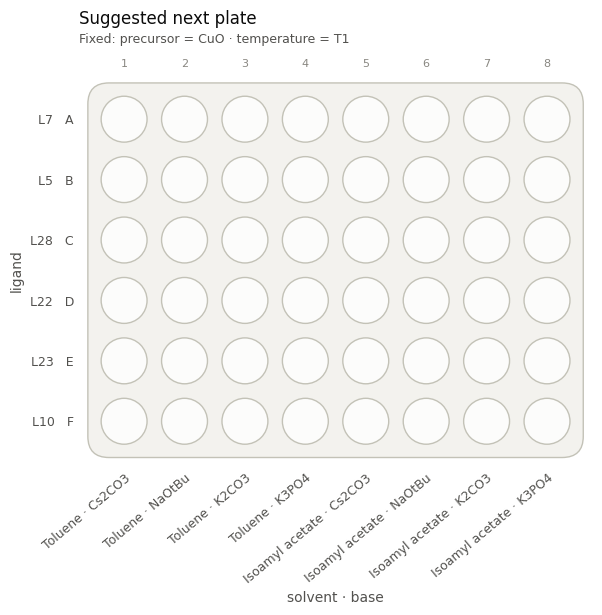

In [10]:
layout = plate_layout(best_design, cond_df)

plot_plate(layout, title="Suggested next plate"); # this would be plate 2 if using only plate 1 train data

The layout is also a table, ready to hand to the lab or save as a CSV. `rxn_id` links each well back to the chemical space.

In [11]:
plate_table = layout[["well", "rxn_id"] + list(analyzer.condition_types)]
# plate_table.to_csv("suggested_plate.csv", index=False)
plate_table.head(10)

,well,rxn_id,ligand,solvent,base,precursor,temperature
0,A1,4264,L7,Toluene,Cs2CO3,CuO,T1
1,A2,4204,L7,Toluene,NaOtBu,CuO,T1
2,A3,4284,L7,Toluene,K2CO3,CuO,T1
3,A4,4224,L7,Toluene,K3PO4,CuO,T1
4,A5,4624,L7,Isoamyl acetate,Cs2CO3,CuO,T1
5,A6,4564,L7,Isoamyl acetate,NaOtBu,CuO,T1
6,A7,4644,L7,Isoamyl acetate,K2CO3,CuO,T1
7,A8,4584,L7,Isoamyl acetate,K3PO4,CuO,T1
8,B1,14824,L5,Toluene,Cs2CO3,CuO,T1
9,B2,14764,L5,Toluene,NaOtBu,CuO,T1
